# Decision Tree Classification — Predicting Loan Repayment

**AI240 · Homework 4 Lab**

**Instructor: Dr. Uma Gajendragadkar**

**Goal:** build a decision tree classifier that predicts whether a loan was repaid (`result`: yes / No) from five numeric features — `initial_payment`, `last_payment`, `credit_score`, `house_number`, and `sum`.

**Dataset: Loan Repayment dataset**
The Loan Repayment dataset is made up of 1000 rows and six columns. Each row represents information about a particular person that relates to loan repayment. This dataset is perfect for classification algorithms such as the decision tree. The six columns are the following.

- Initial payment.
- Last payment.
- Credit score.
- House number.
- Sum.
- Result.

The work follows three phases:
1. **Exploration**: understand the data before modelling it.
2. **Implementation**: encode, split, scale, train, predict.
3. **Evaluation**: accuracy, classification report, and confusion matrix.

# Phase 1 — Exploration

## Import libraries

In [27]:
# Import Libraries
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import LabelEncoder, StandardScaler 
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix

sns.set_style('whitegrid')

## Import data

In [3]:
# Load dataset into a Pandas Dataframe
# Dataset source context: Loans_Dataset.csv containing loans data
df = pd.read_csv('../data/Loans_Dataset.csv')

# Inspect initial structure 
print("--- DataFrame Head ---") 
print(df.head()) 

# Shape and data types
print("\n--- Shape ---")
print(df.shape)
print("\n--- Data Types ---")
print(df.dtypes)

--- DataFrame Head ---
   initial_payment  last_payment  credit_score  house_number    sum result
0              201         10018           250          3046  13515    yes
1              205         10016           395          3044  13660    yes
2              257         10129           109          3251  13746    yes
3              246         10064           324          3137  13771    yes
4              117         10115           496          3094  13822    yes

--- Shape ---
(1004, 6)

--- Data Types ---
initial_payment    int64
last_payment       int64
credit_score       int64
house_number       int64
sum                int64
result               str
dtype: object


The dataset has **1,004 loans** and 6 columns. All five features are numeric; only the target (`result`) is text. Checking missing values before anything else:

In [4]:
# Missing values
print("\n--- Missing Values ---")
print(df.isna().sum())


--- Missing Values ---
initial_payment    0
last_payment       0
credit_score       0
house_number       0
sum                0
result             0
dtype: int64


No missing values anywhere, so no cleaning or imputation is needed for this dataset.

## Describe

In [5]:
print("\n--- Summary Statistics ---") 
print(df.describe())


--- Summary Statistics ---
       initial_payment  last_payment  credit_score  house_number  \
count      1004.000000   1004.000000   1004.000000   1004.000000   
mean        294.662351  12473.009960    528.902390   4041.282869   
std         115.844218   1442.134231    259.681745    618.431417   
min         100.000000  10005.000000    100.000000   3003.000000   
25%         195.750000  11213.500000    302.750000   3546.500000   
50%         290.000000  12467.000000    518.000000   4046.000000   
75%         398.000000  13690.000000    755.000000   4508.750000   
max         500.000000  14999.000000    997.000000   9876.000000   

                 sum  
count    1004.000000  
mean    17744.012948  
std      9594.659715  
min     13515.000000  
25%     16081.250000  
50%     17383.000000  
75%     18608.250000  
max    246789.000000  


Two things stand out in the summary statistics:

- `sum` has an extreme maximum (246,789) compared with its mean (~17,744) — there is at least one very large loan in the data. The box plots below show this directly.
- `house_number` runs up to 9,876 and behaves more like an ID or address number than a measurement — worth remembering when we read the correlations.

## Data Exploration & Feature Selection (Correlation Analysis)

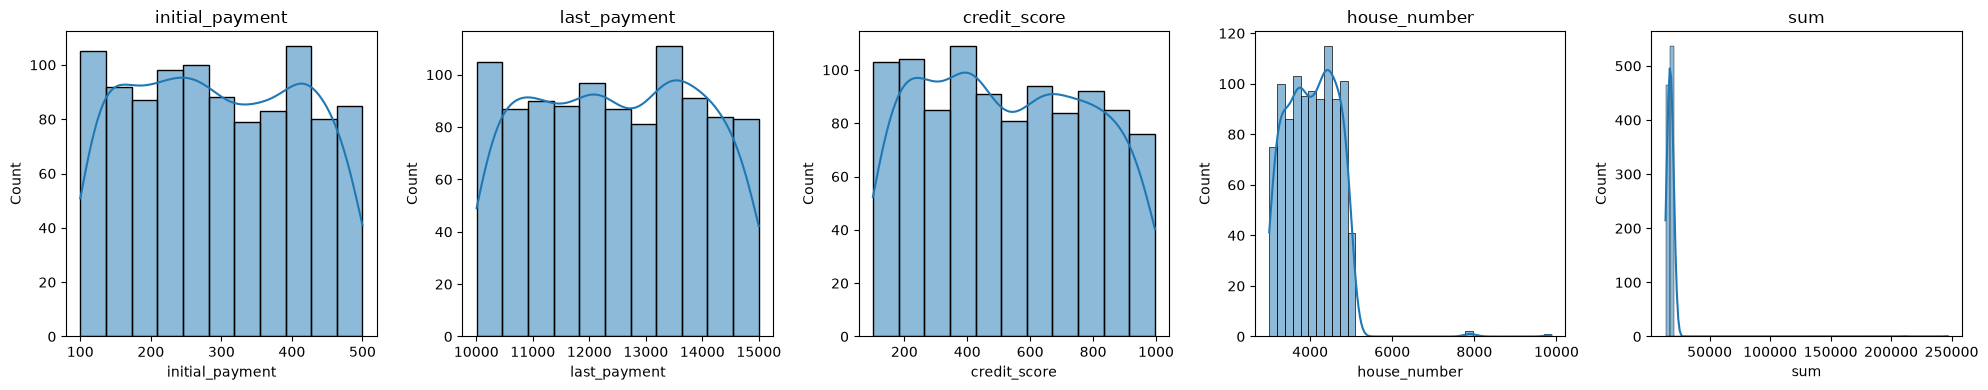

In [6]:
# Distribution of each numeric feature
numeric_cols = ['initial_payment', 'last_payment', 'credit_score', 'house_number', 'sum']
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(x=df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Box plots — checking for outliers

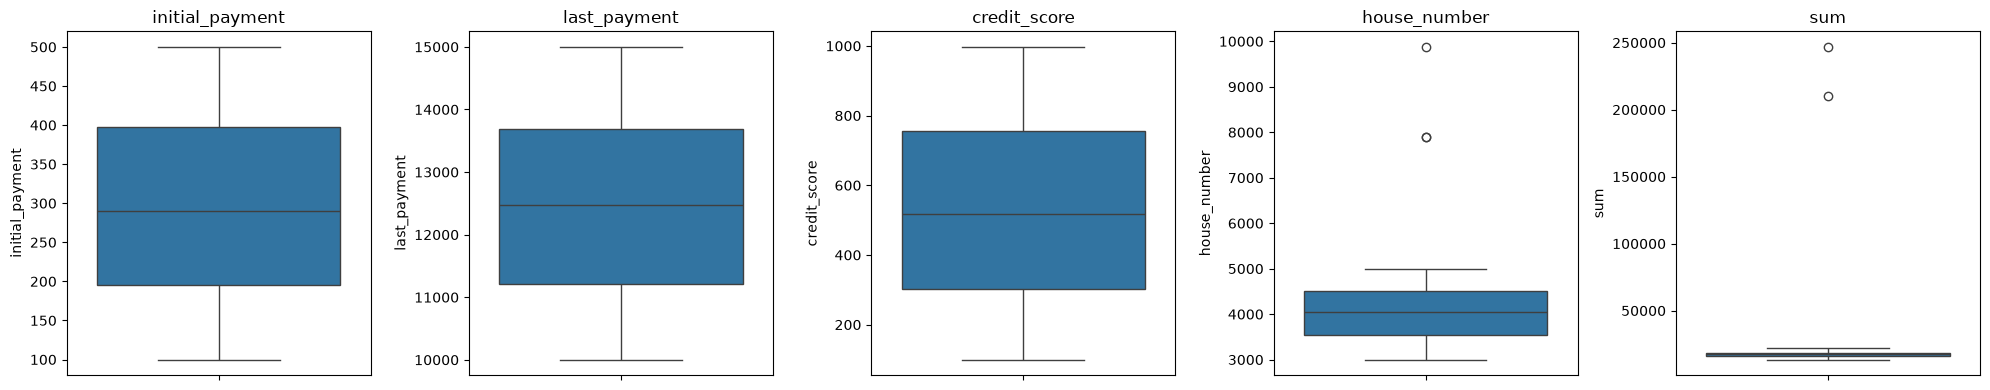

In [7]:
# Box plots for each numeric feature
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

The box plot confirms the `sum` outlier: one loan is many times larger than the rest. Decision trees split on the *order* of values rather than their distances, so a single extreme value does not distort the splits the way it would for a distance-based model; but it is still part of the data story and is noted here rather than silently removed.

## Class balance of the target

In [8]:
# How many loans were repaid vs not repaid?
df['result'].value_counts()

result
No     521
yes    483
Name: count, dtype: int64

The classes are close to balanced (521 not repaid vs 483 repaid), so accuracy is a meaningful headline metric here — unlike a heavily imbalanced problem, a lazy majority-class guess would only score ~52%.

## Correlation matrix

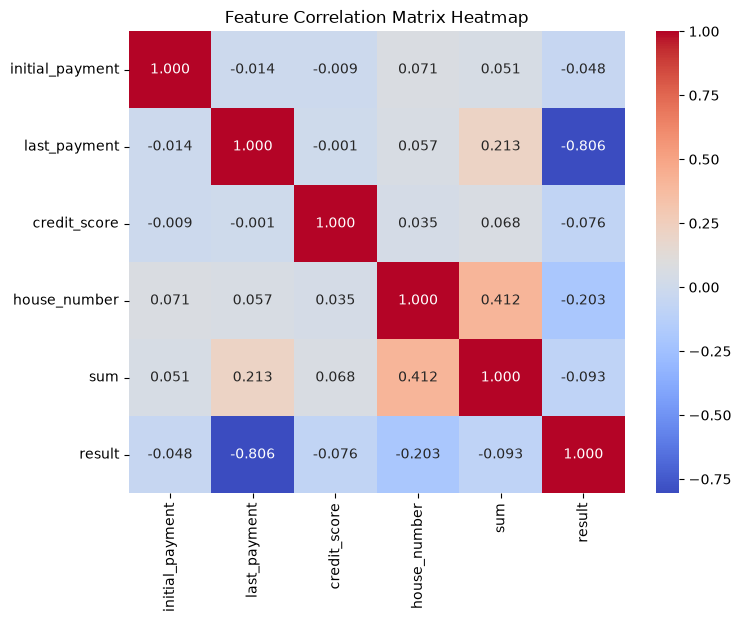

In [9]:
# Correlation matrix (target encoded as 0/1 so it can be included) 
correlation_data = df.copy()
correlation_data['result'] = LabelEncoder().fit_transform(df['result']) # type: ignore
correlation_matrix = correlation_data.corr() 

# Visualize heatmap via Seaborn 
plt.figure(figsize=(8, 6)) 
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".3f") 
plt.title("Feature Correlation Matrix Heatmap") 
plt.show()

Reading the heatmap against the target (`result`):

- **`last_payment` has the strongest linear correlation at about −0.81.** Repaid loans have noticeably lower last payments (about $11,267 on average) than non-repaid loans (about $13,591).
- **`house_number` (−0.20) is a trap.** It looks predictive, but it behaves like an identifier; any pattern it shows is most likely coincidence in this sample, and a tree that splits on ID-like values memorizes rows instead of learning.
- `credit_score` (−0.08) barely moves with the outcome — surprising, since credit score is the feature people expect to matter most.
- `sum` (−0.09) and `initial_payment` (−0.05) look weak **on this measure** — but correlation only detects straight-line relationships. A feature whose effect is a band or a threshold can look weak here and still be powerful for a tree, which is why Phase 3 checks what the tree actually used instead of trusting this table.

## Relationship — last payment vs loan sum, coloured by outcome

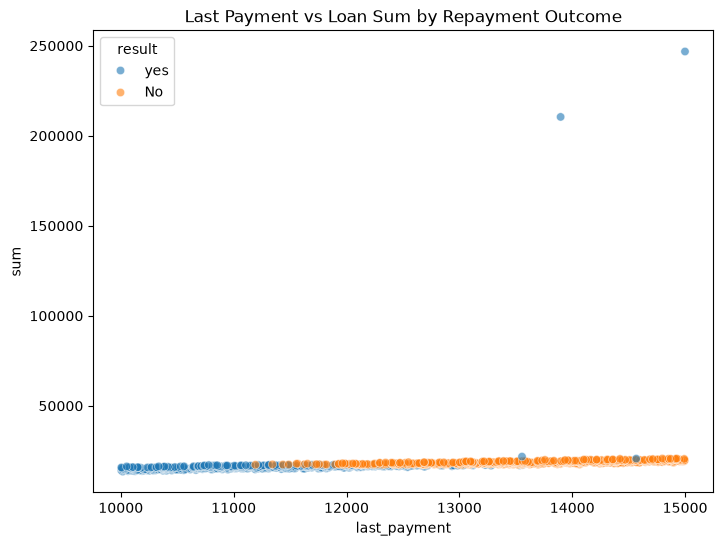

In [10]:
# Scatter: last_payment vs sum, coloured by repayment outcome
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='last_payment', y='sum', hue='result', alpha=0.6)
plt.title('Last Payment vs Loan Sum by Repayment Outcome')
plt.show()

The scatter shows repaid and non-repaid loans occupying visibly different regions along the `last_payment` axis — the pattern behind its strong correlation. Whether the tree splits there first is an empirical question; Phase 3 answers it.

# Phase 2 — Implementation

## Label encoding the target

In [11]:
# Label encoding: No -> 0, yes -> 1
le = LabelEncoder()
df['result'] = le.fit_transform(df['result']) # type: ignore
print('Classes:', list(le.classes_))
df.head()

Classes: ['No', 'yes']


,initial_payment,last_payment,credit_score,house_number,sum,result
0,201,10018,250,3046,13515,1
1,205,10016,395,3044,13660,1
2,257,10129,109,3251,13746,1
3,246,10064,324,3137,13771,1
4,117,10115,496,3094,13822,1


## Independent / dependent variables

In [12]:
# Split data into independent/dependent variables
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values
print('Feature matrix shape:', X.shape)
print('Target shape:', y.shape)

Feature matrix shape: (1004, 5)
Target shape: (1004,)


All five features are kept for the model. `house_number` stays in; the tree itself will decide how much it is worth, and the feature-importance output in Phase 3 shows whether it earned any splits. Dropping it would also be defensible.

## Train / test split

In [13]:
# Split data into train/test sets (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print('Training rows:', len(X_train))
print('Test rows:', len(X_test))

Training rows: 753
Test rows: 251


## Feature scaling

In [14]:
# Scale dataset
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

Scaling is included to follow the course template. Strictly, a decision tree does not need it: each split is a threshold on one feature, and rescaling a feature does not change the order of its values, so the same splits are chosen either way. It is harmless here; and it matters for the distance- and gradient-based models used elsewhere in the course.

## Train the decision tree

In [15]:
# Decision Tree Classification (entropy criterion)
classifier = DecisionTreeClassifier(criterion='entropy', random_state=0)
classifier.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

The tree uses the **entropy** criterion: at each node it chooses the split with the highest information gain; the split that reduces uncertainty about the outcome the most.

## Predict the test set

In [16]:
# Prediction
y_pred = classifier.predict(X_test)
print(np.concatenate((y_pred.reshape(len(y_pred), 1), y_test.reshape(len(y_test), 1)), axis=1)[:15])

[[0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]]


Each row pairs the model's prediction (first column) with the actual outcome (second column) for the first 15 test loans.

# Phase 3 — Evaluation

## Accuracy

In [19]:
# Accuracy
accuracy_score(y_test, y_pred)

0.9960159362549801

## Classification report

In [20]:
# Classification report
print(f'Classification Report: \n{classification_report(y_test, y_pred, target_names=le.classes_)}')

Classification Report: 
              precision    recall  f1-score   support

          No       0.99      1.00      1.00       136
         yes       1.00      0.99      1.00       115

    accuracy                           1.00       251
   macro avg       1.00      1.00      1.00       251
weighted avg       1.00      1.00      1.00       251



## F1 score

In [22]:
# F1 score
print(f"F1 Score : {f1_score(y_test, y_pred)}")

F1 Score : 0.9956331877729258


## Confusion matrix

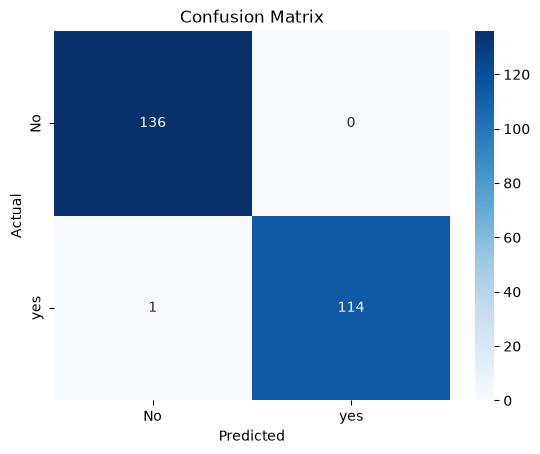

Confusion matrix:
 [[136   0]
 [  1 114]]


In [23]:
# Confusion matrix
cf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(cf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_) # type: ignore
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
print('Confusion matrix:\n', cf_matrix)

## Which features did the tree actually use?

In [24]:
# Feature importances
importances = pd.Series(classifier.feature_importances_, index=numeric_cols).sort_values(ascending=False)
importances

sum                1.0
initial_payment    0.0
last_payment       0.0
credit_score       0.0
house_number       0.0
dtype: float64

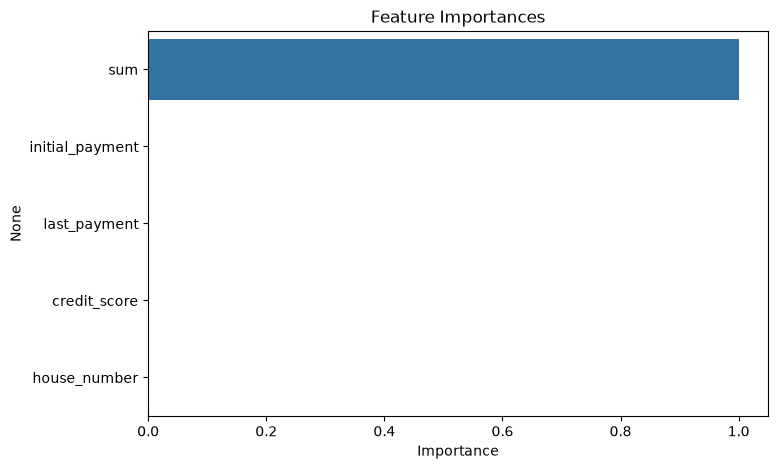

In [25]:
# Feature importance chart
plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index)
plt.title('Feature Importances')
plt.xlabel('Importance')
plt.show()

## The top of the tree

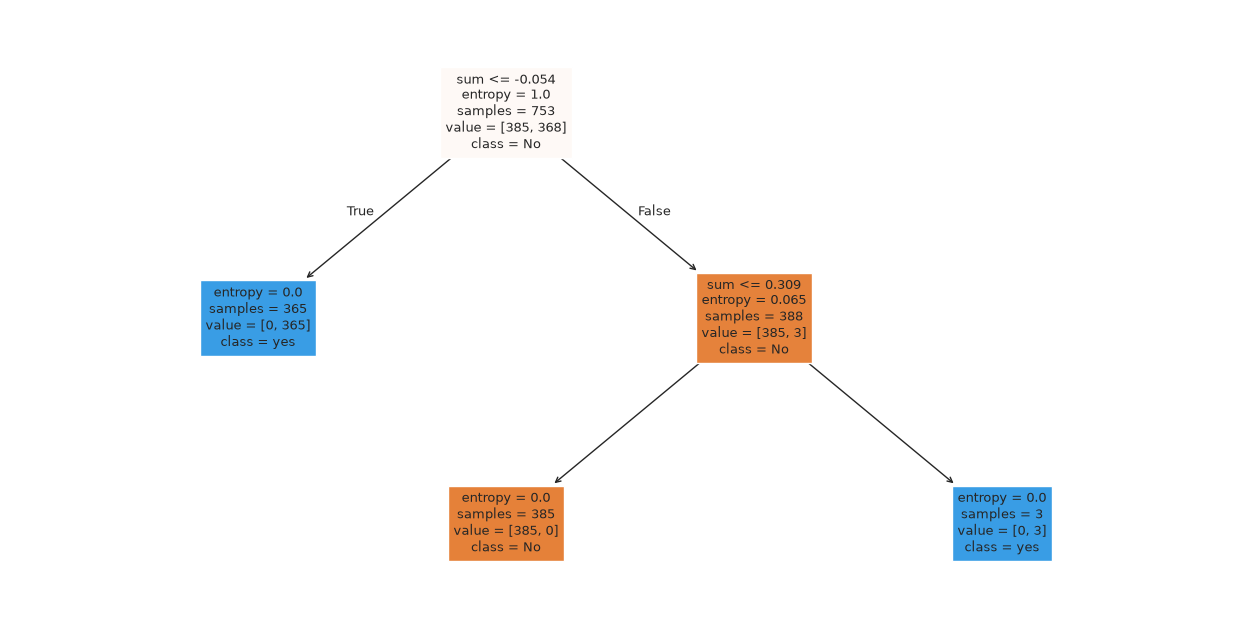

In [28]:
# Visualize the first two levels of the tree
plt.figure(figsize=(16, 8))
plot_tree(classifier, feature_names=numeric_cols, class_names=list(le.classes_),
          filled=True, max_depth=2, fontsize=9)
plt.show()

**The root split is a surprise; and it is the most interesting result in this homework.** The tree ignores `last_payment` completely and splits on `sum` alone:

- `sum` ≤ 17,260 → repaid
- 17,260 < `sum` ≤ 21,261 → not repaid
- `sum` > 21,261 → repaid

The whole tree is only **2 levels deep with 3 leaves**. Looking back at the data explains it: repaid loans cluster in a lower `sum` band (roughly $13.5K–$17.3K) and non-repaid loans in a higher band (roughly $17.3K–$20.7K). That is a *band* relationship, not a straight line; which is exactly why `sum`'s linear correlation with the target was only −0.09 while `last_payment`'s was −0.81. Correlation ranked the features one way; the tree, which searches for thresholds rather than slopes, found the sharper pattern somewhere else. The third leaf exists because of a single loan; the $246,789 outlier from Phase 1 was repaid, so the tree gives very large loans their own branch.

## Discussion — Interpreting the Results

The test accuracy is **250/251 = 99.6%**. The confusion matrix, with rows as actual labels and columns as predictions (`No`, `yes`), is:

| Actual \ Predicted | No | yes |
|---|---:|---:|
| No | 136 | 0 |
| yes | 1 | 114 |

The single error was a **false “No”**: one borrower who repaid was predicted not to repay. There were no false “yes” predictions—no defaulters were predicted to repay. For a lender, approving a borrower who defaults often carries a larger direct financial cost, while rejecting someone who would repay means lost business and can raise fairness concerns. The relative costs depend on the lender and should inform how the model is evaluated and used.

### Why `sum` and not `last_payment`?

The correlation table measures **linear association**: `last_payment` had a stronger correlation with the outcome than `sum`. A decision tree does something different: it searches for thresholds that separate the classes. In this dataset, `sum` appears to have a banded or threshold-based relationship with repayment that the tree can exploit, even though its linear correlation is weak. A correlation heatmap is useful for exploration, but it does not show every predictive pattern and should not be used alone to select features.

### The unused `house_number` feature

`house_number` had zero importance, so this fitted tree made no splits on it. Keeping it was harmless to this tree’s predictions, but that does not make it a good feature. In a real lending model, an ID-like field should generally be excluded or carefully justified: it may encode location or other sensitive proxies, and patterns tied to identifiers may not generalize. Feature choices also require fairness and governance review.

### The outlier leaf: learning or memorizing?

The branch for `sum` above **21,261** appears to rely on essentially one very large repaid loan. That is a warning sign for memorization: the tree may have created a rule for a rare example rather than a pattern that will recur. A lower `max_depth` or higher `min_samples_leaf` could prevent such a small leaf. This might reduce overfitting, but its effect on test accuracy is not knowable in advance; it could improve or reduce it. Compare settings with cross-validation rather than choosing based on this one test score.

### A limitation to keep in mind

These metrics come from a single 75/25 split, so they are **one estimate, not a verdict**. A near-perfect score should prompt checks for data leakage, duplicates, and how the labels were generated—not immediate celebration. Repeated stratified cross-validation and a separate, representative holdout set would give a more reliable picture of performance.